<a href="https://colab.research.google.com/github/romapas03-cyber/rafael/blob/main/actt.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Saving hardware_sales_data (1).xlsx to hardware_sales_data (1) (3).xlsx
Rows, Columns: (300, 15)

===== head() =====


,Product,Quantity,Unit_Price,Total_Sales,Date,Payment,Customer_Type,Order_Status,Category,Brand,Size,Discount,Channel,Discount_Pct,Sale_Month,Sale_Weekday
0,Circular Saw,19,2182.30,39390.51,2025-01-02,Cash,Wholesale,Completed,Power Tools,Makita,7-1/4 in,5%,Physical Store,5.0,1,3
1,Faucet,38,1401.78,42614.11,2025-01-04,Cash,Walk-in,Completed,Plumbing,Moen,Standard,20%,Phone,20.0,1,5
2,Padlock,36,1162.12,41836.32,2025-01-04,GCash,Retail,Completed,Hardware,Master Lock,40mm,0%,Physical Store,0.0,1,5
3,Angle Grinder,31,1628.15,50472.65,2025-01-04,Cash,Walk-in,Completed,Power Tools,Bosch,4.5 in,0%,Phone,0.0,1,5
4,Sandpaper Pack,49,2884.82,134288.37,2025-01-04,Cash,Contractor,Completed,Painting Supplies,3M,10-sheet,5%,Phone,5.0,1,5



===== info() =====
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 300 entries, 0 to 299
Data columns (total 16 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   Product        300 non-null    object        
 1   Quantity       300 non-null    int64         
 2   Unit_Price     300 non-null    float64       
 3   Total_Sales    300 non-null    float64       
 4   Date           300 non-null    datetime64[ns]
 5   Payment        300 non-null    object        
 6   Customer_Type  300 non-null    object        
 7   Order_Status   300 non-null    object        
 8   Category       300 non-null    object        
 9   Brand          300 non-null    object        
 10  Size           300 non-null    object        
 11  Discount       300 non-null    object        
 12  Channel        300 non-null    object        
 13  Discount_Pct   300 non-null    float64       
 14  Sale_Month     300 non-null    int32         
 15  Sal

,Quantity,Unit_Price,Total_Sales,Date,Discount_Pct,Sale_Month,Sale_Weekday
count,300.000000,300.000000,300.000000,300,300.000000,300.000000,300.000000
mean,25.836667,2490.684067,61499.094233,2025-07-11 06:19:12,7.483333,6.823333,3.026667
min,1.000000,57.250000,545.130000,2025-01-02 00:00:00,0.000000,1.000000,0.000000
25%,16.000000,1244.452500,15866.530000,2025-04-01 18:00:00,0.000000,4.000000,1.000000
50%,26.000000,2362.670000,50003.440000,2025-07-20 00:00:00,5.000000,7.000000,3.000000
75%,37.000000,3806.692500,90192.982500,2025-10-11 12:00:00,15.000000,10.000000,5.000000
max,50.000000,4996.420000,210534.710000,2025-12-30 00:00:00,20.000000,12.000000,6.000000
std,13.445169,1447.621448,53220.339258,NaN,7.644903,3.514726,1.938681



INDEPENDENT VARIABLES (features): ['Quantity', 'Unit_Price', 'Discount_Pct', 'Payment', 'Customer_Type', 'Order_Status', 'Category', 'Brand', 'Channel', 'Sale_Month', 'Sale_Weekday']
DEPENDENT VARIABLE (target): High_Sales (1 = High, 0 = Low)
High_Sales
0    150
1    150
Name: count, dtype: int64

Train size: (240, 44)  Test size: (60, 44)

Model trained!


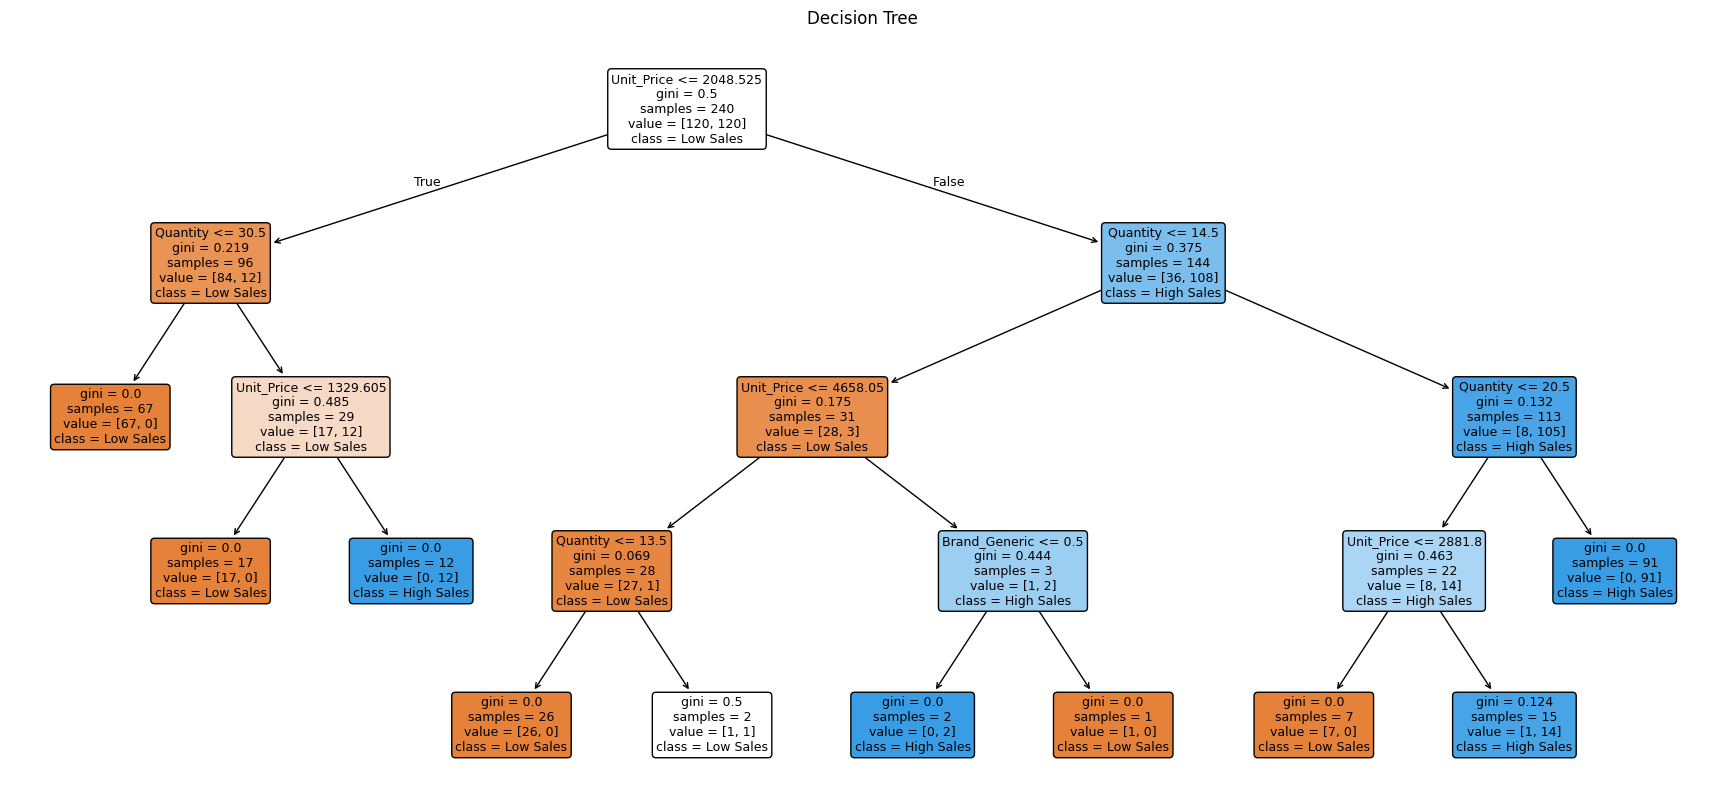


Sample predictions:


,Actual,Predicted
0,0,0
1,0,0
2,0,0
3,0,0
4,0,1
5,0,0
6,1,1
7,0,0
8,1,1
9,0,0


Test accuracy:  96.67%
Train accuracy: 99.17%


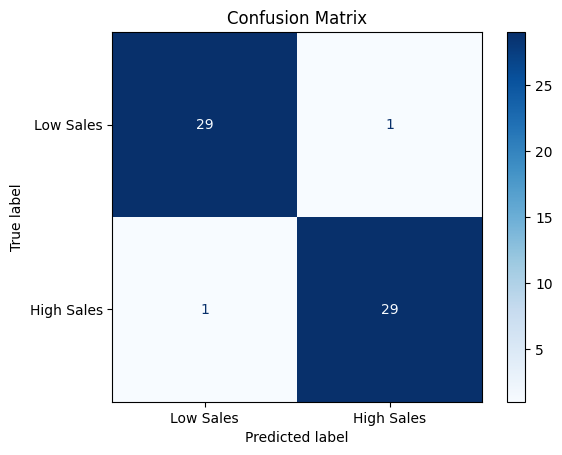

              precision    recall  f1-score   support

   Low Sales       0.97      0.97      0.97        30
  High Sales       0.97      0.97      0.97        30

    accuracy                           0.97        60
   macro avg       0.97      0.97      0.97        60
weighted avg       0.97      0.97      0.97        60

Top 10 feature importance:
Unit_Price                 0.594
Quantity                   0.395
Brand_Generic              0.011
Discount_Pct               0.000
Sale_Weekday               0.000
Payment_GCash              0.000
Customer_Type_Retail       0.000
Customer_Type_Walk-in      0.000
Customer_Type_Wholesale    0.000
Order_Status_Completed     0.000
dtype: float64


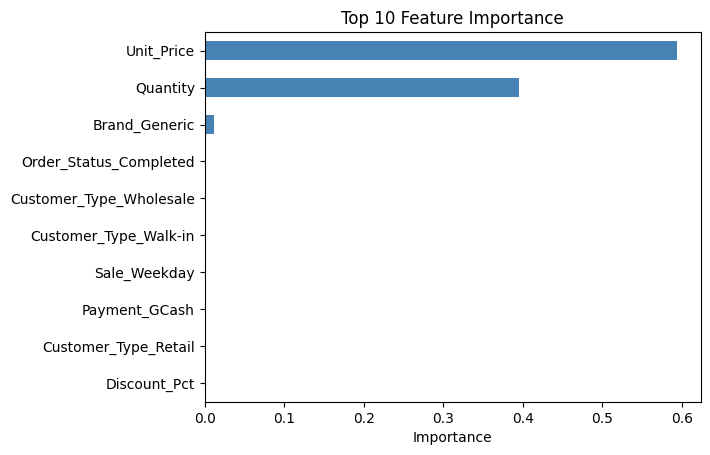


===== RESULTS SUMMARY =====
Test accuracy: 96.67%
Correct predictions: 58 out of 60
Wrong predictions: 2 (False Positive: 1, False Negative: 1)
Top variable: Unit_Price (59%)
Second variable: Quantity (39%)


In [ ]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
from google.colab import files
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (accuracy_score, confusion_matrix,
                             classification_report, ConfusionMatrixDisplay)


uploaded = files.upload()
df = pd.read_excel(list(uploaded.keys())[0])
print("Rows, Columns:", df.shape)

df = df.rename(columns={
    'Product Name/Type': 'Product',
    'Quantity Sold': 'Quantity',
    'Unit Price': 'Unit_Price',
    'Total Sales': 'Total_Sales',
    'Date of Sale': 'Date',
    'Payment Method': 'Payment',
    'Customer Category': 'Customer_Type',
    'Order Status': 'Order_Status',
    'Product Category': 'Category',
    'Product Size/Specification': 'Size',
    'Discount Applied': 'Discount',
    'Sales Channel': 'Channel',
})

df = df.drop_duplicates().dropna()

df = df.drop(columns=[c for c in df.columns if df[c].nunique() == 1])

df['Date'] = pd.to_datetime(df['Date'])
df['Discount_Pct'] = df['Discount'].astype(str).str.replace('%', '').astype(float)
df['Sale_Month'] = df['Date'].dt.month
df['Sale_Weekday'] = df['Date'].dt.dayofweek
df = df.sort_values('Date').reset_index(drop=True)

print("\n===== head() ====="); display(df.head())
print("\n===== info() ====="); df.info()
print("\n===== describe() ====="); display(df.describe())

df['High_Sales'] = (df['Total_Sales'] > df['Total_Sales'].median()).astype(int)

feature_cols = ['Quantity', 'Unit_Price', 'Discount_Pct', 'Payment', 'Customer_Type',
                'Order_Status', 'Category', 'Brand', 'Channel',
                'Sale_Month', 'Sale_Weekday']
X = pd.get_dummies(df[feature_cols], drop_first=True)
y = df['High_Sales']
print("\nINDEPENDENT VARIABLES (features):", feature_cols)
print("DEPENDENT VARIABLE (target): High_Sales (1 = High, 0 = Low)")
print(y.value_counts())

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)
print("\nTrain size:", X_train.shape, " Test size:", X_test.shape)

model = DecisionTreeClassifier(max_depth=4, random_state=42)

model.fit(X_train, y_train)
print("\nModel trained!")

plt.figure(figsize=(22, 10))
plot_tree(model, feature_names=X.columns, class_names=['Low Sales', 'High Sales'],
          filled=True, rounded=True, fontsize=9)
plt.title("Decision Tree")
plt.show()

y_pred = model.predict(X_test)
print("\nSample predictions:")
display(pd.DataFrame({'Actual': y_test.values[:10], 'Predicted': y_pred[:10]}))

acc = accuracy_score(y_test, y_pred)
print(f"Test accuracy:  {acc:.2%}")
print(f"Train accuracy: {model.score(X_train, y_train):.2%}")

cm = confusion_matrix(y_test, y_pred)
ConfusionMatrixDisplay(cm, display_labels=['Low Sales', 'High Sales']).plot(cmap='Blues')
plt.title("Confusion Matrix")
plt.show()

print(classification_report(y_test, y_pred, target_names=['Low Sales', 'High Sales']))

imp = pd.Series(model.feature_importances_, index=X.columns).sort_values(ascending=False)
print("Top 10 feature importance:")
print(imp.head(10).round(3))
imp.head(10).sort_values().plot(kind='barh', color='steelblue', title='Top 10 Feature Importance')
plt.xlabel("Importance")
plt.show()

tn, fp, fn, tp = cm.ravel()
print("\n===== RESULTS SUMMARY =====")
print(f"Test accuracy: {acc:.2%}")
print(f"Correct predictions: {tn + tp} out of {len(y_test)}")
print(f"Wrong predictions: {fp + fn} (False Positive: {fp}, False Negative: {fn})")
print(f"Top variable: {imp.index[0]} ({imp.iloc[0]:.0%})")
print(f"Second variable: {imp.index[1]} ({imp.iloc[1]:.0%})")

### Key Findings & Business Recommendations

#### **Key Findings**
1. **High Model Accuracy**: The Decision Tree model correctly classified **96.7%** of the transactions in the test dataset, showing strong predictive performance.
2. **Primary Revenue Drivers**: The target variable (High Sales vs. Low Sales) is overwhelmingly determined by **Unit Price** (accounting for **59.4%** of the model's decision-making weight) and **Quantity Sold** (**39.5%**).
3. **Minor Features**: Other factors like specific brands (e.g., Generic brands at **1.1%**), payment methods, or sales channels have negligible or zero direct influence compared to core pricing and purchase volume.

#### **Business Recommendations**
1. **Optimized Stocking & Inventory Selection**:
   Prioritize stocking high-priced, premium items and products that customers naturally purchase in bulk quantities, as these are the primary drivers of high-value sales.
   
2. **B2B Bulk-Purchase Incentives**:
   Actively target Wholesale and Contractor customer segments with bulk-purchase deals or exclusive wholesale volume discounts to maximize order sizes.
   
3. **Strategic Discounting**:
   Apply discounts strategically to boost order volume (Quantity) rather than marking down items that already sell at high price points without resistance.
   
4. **Operations & Lifecycle Management**:
   Implement a rigorous follow-up system for Cancelled, Returned, and Pending orders to minimize revenue leakage on high-potential transactions.
   
5. **Continuous Model Improvement**:
   Retrain the prediction model regularly with updated sales data and evaluate more complex models like Random Forest to see if performance can be improved even further.